In [1]:
# Install dependencies (run once)
%pip install tabpfn shap xgboost missforest openpyxl joblib --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 13.6 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 595.9/595.9 kB 25.6 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder,PowerTransformer,QuantileTransformer,MinMaxScaler
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.metrics import r2_score, mean_squared_error
from missforest import MissForest
from xgboost import XGBRegressor
import shap as s
from sklearn.inspection import PartialDependenceDisplay
from sklearn.model_selection import cross_val_predict
from scipy.optimize import differential_evolution
from scipy.spatial.distance import cdist
from itertools import combinations
import random
from joblib import Parallel, delayed
import multiprocessing
import optuna as op
# Reproducibility
RANDOM_STATE = 62

# Column config — centralised so changes propagate everywhere
TARGET_COL   = 'f_SAR_W_g'
CAT_COLS      = ['c_shape_type', 'c_magnetic_phase', 'c_coating']
DROP_COLS     = ['-', 'DOI', 'c_core_composition', 'c_dopant_element', 'f_dopant_ratio']
FEATURE_NAMES = [
    'f_avg_core_width_nm', 'f_Ms_emu_g_MNP', 'f_Hc_Oe', 'is_doped',
    'c_coating', 'f_H_Oe', 'f_FCY_kHz', 'f_conc_MNP_mg_mL',
    'c_shape_type', 'c_magnetic_phase', 'f_avg_core_sd_nm _BOTH',
    'Ca_comp', 'Co_comp', 'Cu_comp', 'Fe_comp', 'Ga_comp', 'Gd_comp',
    'Mg_comp', 'Mn_comp', 'Nd_comp', 'Ni_comp', 'Sn_comp', 'Tb_comp',
    'Zn_comp', 'f_magnetic_anisotropy', 'f_magnetic_dipole_moment',
]

In [3]:
def clean_column_names(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = [
        c.replace('\ufeff', '').replace('\u200b', '').strip()
        for c in df.columns
    ]
    return df


df_raw = pd.read_excel("/kaggle/input/datasets/magneticmaterials/hyperthermia/Final.xlsx")
df_raw = clean_column_names(df_raw)

# Drop identifier/non-feature columns that exist in this dataset
cols_to_drop = [c for c in DROP_COLS if c in df_raw.columns]
df = df_raw.drop(columns=cols_to_drop)

print(f"Loaded {df.shape[0]} rows × {df.shape[1]} columns")
df.head()

Loaded 1548 rows × 33 columns


,S. No.,f_avg_core_width_nm,f_Ms_emu_g_MNP,f_Hc_Oe,is_doped,f_is_coated,f_is_organic,f_is_inorganic,f_is_composite_coating,c_coating,...,Fe_comp,Ga_comp,Gd_comp,Mg_comp,Mn_comp,Nd_comp,Ni_comp,Sn_comp,Tb_comp,Zn_comp
0,1,15.0,60.00,0.0,0,0,0,0,0,NaN,...,3.00,0.0,0.00,0.0,0.0,0.0,0.0,0,0.0,0.0
1,2,17.0,36.78,6.0,1,1,1,0,0,Chitosan,...,2.93,0.0,0.07,0.0,0.0,0.0,0.0,0,0.0,0.0
2,3,75.0,60.00,100.0,0,0,0,0,0,NaN,...,3.00,0.0,0.00,0.0,0.0,0.0,0.0,0,0.0,0.0
3,4,19.9,53.10,4.0,0,1,1,0,0,TREG-coated,...,2.00,0.0,0.00,0.0,0.0,0.0,0.0,0,0.0,0.0
4,5,14.6,54.40,3.0,0,0,0,0,0,NaN,...,3.00,0.0,0.00,0.0,0.0,0.0,0.0,0,0.0,0.0


In [4]:
target_col = TARGET_COL.replace('\ufeff', '').replace('\u200b', '').strip()
X = df.drop(columns=[target_col])
y = df[target_col]

# 80 / 10 / 10 split
x_train, x_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE
)

print(f"Train : {x_train.shape[0]} rows")
print(f"Val   : {x_val.shape[0]} rows")
print(f"Test  : {x_test.shape[0]} rows  ← locked until final evaluation")

Train : 1238 rows
Val   : 155 rows
Test  : 155 rows  ← locked until final evaluation


In [5]:
# --- 5a. Binary presence indicators (fit-free, safe to apply before split logic) ---
def add_presence_flags(df_in: pd.DataFrame) -> pd.DataFrame:
    df_out = df_in.copy()
    df_out['f_is_coated']  = df_out['c_coating'].notna().astype(int)
    df_out['f_is_shaped']  = df_out['c_shape_type'].notna().astype(int)
    df_out['f_is_phased']  = df_out['c_magnetic_phase'].notna().astype(int)
    return df_out

x_train = add_presence_flags(x_train)
x_val   = add_presence_flags(x_val)
x_test  = add_presence_flags(x_test)

In [6]:
# --- 5b. Categorical encoding ---
# Fill NaN → 'Unknown' for unseen categories, then ordinal-encode.
# Where the presence flag == 0 (field was missing), force the encoded value to -1.
# Encoders are fit on train only.

def encode_categorical(train_df, val_df, test_df, cat_col, flag_col):
    for df_part in [train_df, val_df, test_df]:
        df_part[cat_col] = df_part[cat_col].fillna('Unknown').astype(str)

    enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    train_df[cat_col] = enc.fit_transform(train_df[[cat_col]])
    val_df[cat_col]   = enc.transform(val_df[[cat_col]])
    test_df[cat_col]  = enc.transform(test_df[[cat_col]])

    for df_part in [train_df, val_df, test_df]:
        df_part.loc[df_part[flag_col] == 0, cat_col] = -1
        df_part.drop(columns=[flag_col], inplace=True)

    return train_df, val_df, test_df

x_train, x_val, x_test = encode_categorical(x_train, x_val, x_test, 'c_coating',       'f_is_coated')
x_train, x_val, x_test = encode_categorical(x_train, x_val, x_test, 'c_shape_type',    'f_is_shaped')
x_train, x_val, x_test = encode_categorical(x_train, x_val, x_test, 'c_magnetic_phase', 'f_is_phased')

print("Encoding done. x_train shape:", x_train.shape)

Encoding done. x_train shape: (1238, 31)


In [8]:
# --- 6a. Feature scaling (QuantileTransformer, fit on train only) ---
transf = QuantileTransformer(random_state=RANDOM_STATE)

x_train_scaled = transf.fit_transform(x_train)
x_val_scaled   = transf.transform(x_val)
x_test_scaled  = transf.transform(x_test)

print("Scaling done. Train shape:", x_train_scaled.shape)

Scaling done. Train shape: (1238, 31)


In [9]:
# --- 6b. Log transformation ---
y_train_log = np.log1p(y_train.values.astype(float))   # log1p on raw SAR
y_val_log   = np.log1p(y_val.values.astype(float))
y_test_log  = np.log1p(y_test.values.astype(float))

scaler = MinMaxScaler()
y_train_scaled = scaler.fit_transform(y_train_log.reshape(-1, 1)).flatten()
y_val_scaled   = scaler.transform(y_val_log.reshape(-1, 1)).flatten()
y_test_scaled  = scaler.transform(y_test_log.reshape(-1, 1)).flatten()

print("=== Scaler sanity check ===")
print(f"  data_min_ : {scaler.data_min_[0]:.4f}  "
      f"(= log1p({np.expm1(scaler.data_min_[0]):.2f} W/g)")
print(f"  data_max_ : {scaler.data_max_[0]:.4f}  "
      f"(= log1p({np.expm1(scaler.data_max_[0]):.2f} W/g)")
assert scaler.data_max_[0] > 1.0, \
    "Scaler data_max_ is still wrong — y_train may still be pre-transformed. Restart kernel and rerun top-to-bottom."

# Use these as your targets for model training (rename to match rest of notebook)
y_train = y_train_scaled
y_val   = y_val_scaled
y_test  = y_test_scaled


=== Scaler sanity check ===
  data_min_ : 0.1570  (= log1p(0.17 W/g)
  data_max_ : 8.6145  (= log1p(5510.00 W/g)


In [10]:
def inverse_sar(y_scaled: np.ndarray, fitted_scaler: MinMaxScaler) -> np.ndarray:
  y_scaled_clipped = np.clip(y_scaled, 0.0, 1.0)
  pred_log_units      = fitted_scaler.inverse_transform(y_scaled_clipped.reshape(-1, 1)).flatten()
  true_predicted_sar  = np.expm1(pred_log_units)
  return true_predicted_sar

In [12]:
def objective(trial):
    params = dict(
        n_estimators     = trial.suggest_int('n_estimators', 50, 1000),
        learning_rate    = trial.suggest_float('learning_rate', 1e-3, 0.1, log=True),
        max_depth        = trial.suggest_int('max_depth', 3, 15),
        min_child_weight = trial.suggest_int('min_child_weight', 1, 20),
        subsample        = trial.suggest_float('subsample', 0.5, 1.0),
        colsample_bytree = trial.suggest_float('colsample_bytree', 0.5, 1.0)
    )
    
    xgb = XGBRegressor(**params, random_state=RANDOM_STATE, n_jobs=-1)
    
    xgb.fit(x_train_scaled, y_train)
    
    preds = xgb.predict(x_val_scaled)
    
    rmse = np.sqrt(mean_squared_error(y_val, inverse_sar(preds, scaler)))
    
    return rmse

study = op.create_study(
    direction='minimize',
    sampler=op.samplers.TPESampler(seed=RANDOM_STATE),
    storage='sqlite:///xgb_regression_optuna.db',
    load_if_exists=True,
)

study.optimize(objective, n_trials=50) 

print("Best params :", study.best_params)
print("Best val RMSE:", round(study.best_value, 4))

[I 2026-10-12 08:16:09,111] A new study created in RDB with name: no-name-db520e11-2f5c-4f10-9bf7-800c428b5bd4
[I 2026-10-12 08:16:09,503] Trial 0 finished with value: 78.87569454335377 and parameters: {'n_estimators': 82, 'learning_rate': 0.009510755474627637, 'max_depth': 13, 'min_child_weight': 9, 'subsample': 0.8157076868653823, 'colsample_bytree': 0.645471618633067}. Best is trial 0 with value: 78.87569454335377.
[I 2026-10-12 08:16:10,210] Trial 1 finished with value: 91.63329831865177 and parameters: {'n_estimators': 566, 'learning_rate': 0.0028599784439653853, 'max_depth': 6, 'min_child_weight': 20, 'subsample': 0.8229052160825424, 'colsample_bytree': 0.5089285767457075}. Best is trial 0 with value: 78.87569454335377.
[I 2026-10-12 08:16:13,449] Trial 2 finished with value: 209.22899304087144 and parameters: {'n_estimators': 997, 'learning_rate': 0.029538542953462348, 'max_depth': 12, 'min_child_weight': 9, 'subsample': 0.6018900964197451, 'colsample_bytree': 0.9810512645192612

Best params : {'n_estimators': 75, 'learning_rate': 0.0010018838196974328, 'max_depth': 15, 'min_child_weight': 13, 'subsample': 0.9226512426335954, 'colsample_bytree': 0.8061102020552042}
Best val RMSE: 59.5003


In [13]:
xgb = XGBRegressor(**study.best_params, random_state=RANDOM_STATE, n_jobs=-1)
xgb.fit(x_train_scaled, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8061102020552042, device=None,
             early_stopping_rounds=None, enable_categorical=True,
             eval_metric=None, feature_types=None, feature_weights=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.0010018838196974328,
             max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=15, max_leaves=None,
             min_child_weight=13, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=75, n_jobs=-1,
             num_parallel_tree=None, ...)

In [14]:
y_val_pred  = xgb.predict(x_val_scaled)
y_test_pred = xgb.predict(x_test_scaled)

val_r2    = r2_score(y_val,  y_val_pred)
test_r2   = r2_score(y_test, y_test_pred)
val_rmse  = np.sqrt(mean_squared_error(y_val, y_val_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

y_test_inv      = inverse_sar(y_test, scaler)
y_test_pred_inv = inverse_sar(y_test_pred, scaler)
err_90          = np.quantile(np.abs(y_test_inv - y_test_pred_inv), 0.90)

print(f"Validation  — R²: {val_r2:.4f}   RMSE: {val_rmse:.4f}")
print(f"Test        — R²: {test_r2:.4f}   RMSE: {test_rmse:.4f}")
print(f"90th-pct prediction error (test): ±{err_90:.4f}")

Validation  — R²: 0.0612   RMSE: 0.1623
Test        — R²: 0.0784   RMSE: 0.1532
90th-pct prediction error (test): ±243.5690


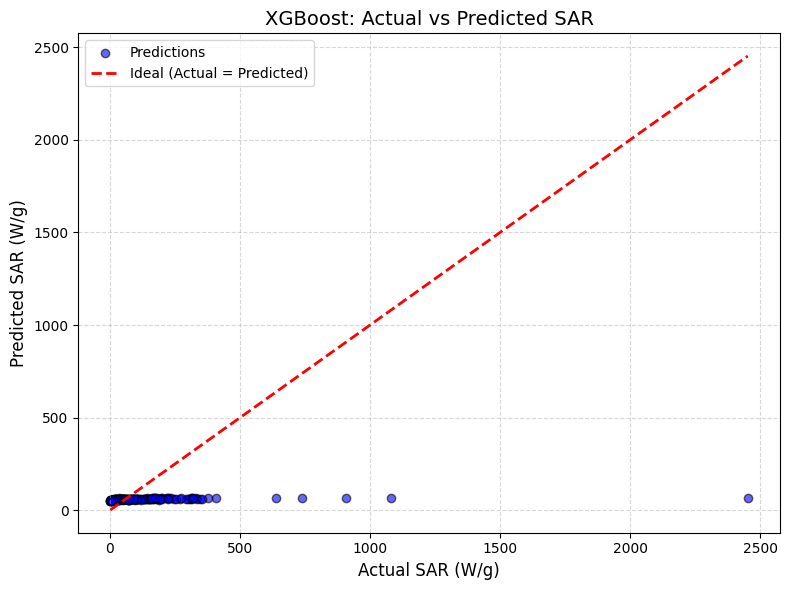

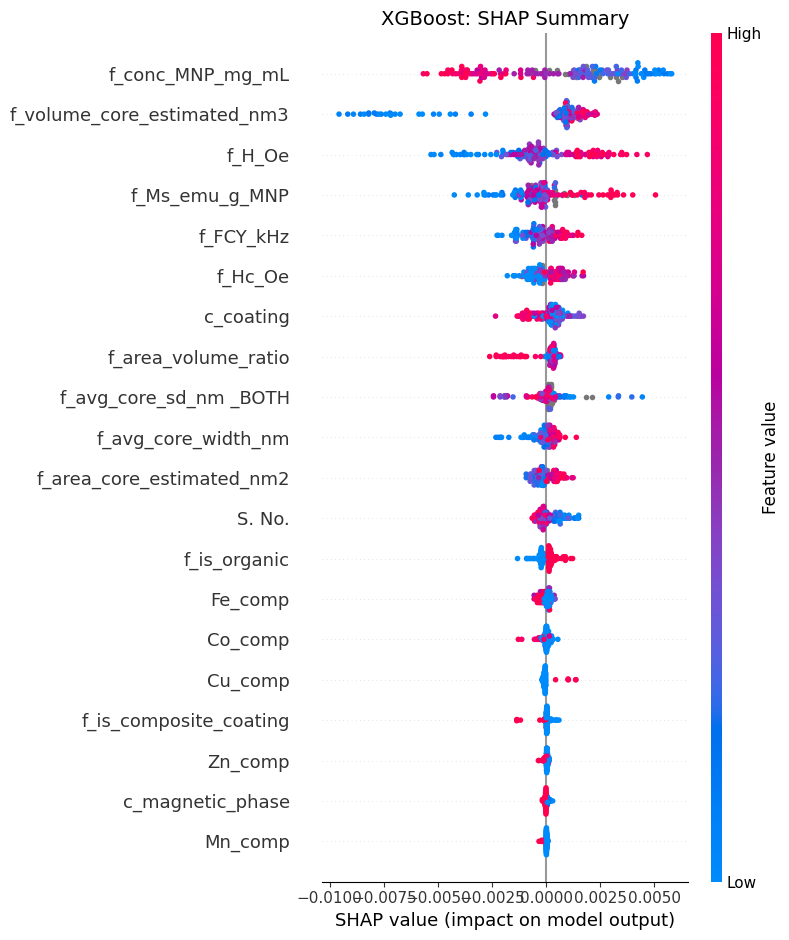

In [15]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test_inv, y_test_pred_inv, alpha=0.6, color='blue', edgecolor='k', label='Predictions')
min_val = min(np.min(y_test_inv), np.min(y_test_pred_inv))
max_val = max(np.max(y_test_inv), np.max(y_test_pred_inv))
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ideal (Actual = Predicted)')
plt.title('XGBoost: Actual vs Predicted SAR', fontsize=14)
plt.xlabel('Actual SAR (W/g)', fontsize=12)
plt.ylabel('Predicted SAR (W/g)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('xgb_actual_vs_predicted.png', dpi=600, bbox_inches='tight')
plt.show()
plt.close()

explainer = s.TreeExplainer(xgb)
shap_values = explainer.shap_values(x_test_scaled)
plt.figure(figsize=(10, 8))
s.summary_plot(shap_values, x_test_scaled, feature_names=x_test.columns, show=False)
plt.title('XGBoost: SHAP Summary', fontsize=14)
plt.tight_layout()
plt.savefig('xgb_shap_summary.png', dpi=600, bbox_inches='tight')
plt.show()
plt.close()